In [222]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import rcParams
import time
from copy import copy as dup
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit
from pint import UnitRegistry; AssignQuantity = UnitRegistry().Quantity
from importlib import reload
from matplotlib.gridspec import GridSpec
from time import time

# My modules
import sys; sys.path.append('..')
import importlib  # Import the importlib module
import QLCstuff as QLC
import f90nml

In [223]:
# Graphics parameters
%matplotlib inline
ticklabelsize = 11
fontsize = 15
linewidth = 2

In [224]:
def f1d_solve_ivp(t, y, scalar_params, sigmaI, j2_list):
    Nbar, Nstar, sigma0, nu_kin_mlyperus, DoverdeltaX2, tau_eq = scalar_params
    l = int(len(y)/2)
    NQLL0 = y[:l]
    Ntot0 = y[l:]
    
    # Ntot deposition
    m = (NQLL0 - (Nbar - Nstar))/(2*Nstar)
    sigma_m = (sigmaI - m * sigma0)
    dNtot_dt = nu_kin_mlyperus * sigma_m

    # Ntot diffusion in x-space (replaced by the FT code below this)
    dy = np.empty(np.shape(NQLL0))
    for i in range(1,len(NQLL0)-1):
        dy[i] = DoverdeltaX2*(NQLL0[i-1]-2*NQLL0[i]+NQLL0[i+1])
    dy[0]  = DoverdeltaX2*(NQLL0[-1] -2*NQLL0[0] +NQLL0[1]) # Periodic BC
    dy[-1] = DoverdeltaX2*(NQLL0[-2] -2*NQLL0[-1]+NQLL0[0])

    # Diffusion term based on FT
    # Dcoefficient1 = 4*DoverdeltaX2/l**2*np.pi**2; #print('Dcoefficient1', Dcoefficient1)
    # bj_list = rfft(NQLL0)
    # cj_list = bj_list*j2_list
    # dy = -Dcoefficient1  * irfft(cj_list)

    # Combined
    # print('from f1d_solve_ivp: shapes are ', np.shape(dNtot_dt), np.shape(dy))
    dNtot_dt += dy

    # NQLL

    dNQLL_dt = dNtot_dt - QLC.getDeltaNQLL(Ntot0,Nstar,Nbar,NQLL0)/t_eq_array #!!!
    # dNQLL_dt = dNtot_dt - QLC.getDeltaNQLL(Ntot0,Nstar,Nbar,NQLL0)/tau_eq #!!!
    
    # Package for output
    return np.concatenate((dNQLL_dt, dNtot_dt))

def run_f1d(\
           NQLL_init_1D,Ntot_init_1D,times,\
           Nbar, Nstar, sigma0, nu_kin_mlyperus, Doverdeltax2, tau_eq, sigmaI,\
           AssignQuantity,\
           verbose=0, odemethod='RK45'):

    """ Solves the QLC-2 problem. Branched from the code in diffusionstuff11.py, it has units """

    # Prep for the integration
    nt = len(times)
    nx = len(NQLL_init_1D)
    ylast = np.array([NQLL_init_1D,Ntot_init_1D])
    ylast = np.reshape(ylast,2*nx)
    ykeep_1D = [ylast]
    lastprogress = 0
    sigmaI_mag = sigmaI.to('dimensionless').magnitude
    sigma0_mag = sigma0.to('dimensionless').magnitude
    print(sigmaI[0],sigmaI_mag[0],sigma0_mag)
    t1 = time()
    bj_list = QLC.rfft(NQLL_init_1D)
    j_list = np.array([j for j in range(len(bj_list))])
    j2_list = np.array(j_list)**2

    # Bundle parameters for ODE solver
    scalar_params = np.array(\
            [Nbar, Nstar, sigma0_mag, nu_kin_mlyperus.magnitude, Doverdeltax2.magnitude, tau_eq.magnitude])

    # Loop over times
    for i in range(0,nt-1):
                
        # Specify the time interval of this step
        tinterval = [times[i].magnitude,times[i+1].magnitude]
        
        if verbose > 0:
            print(tinterval)
            print(ylast)
            print(scalar_params)
            print(sigmaI_mag)
            print(odemethod)
        
        # Integrate up to next time step
        sol = solve_ivp(\
            f1d_solve_ivp, tinterval, ylast, args=(scalar_params, sigmaI_mag, j2_list), \
            rtol=1e-12, method=odemethod) #!!!
        ylast = sol.y[:,-1]
        
        # Symmetrizing
        ylast = np.array(ylast, dtype=np.complex128)
        ylast_reshaped = np.reshape(ylast,(2,nx))
        NQLL_last = ylast_reshaped[0,:]
        Ntot_last = ylast_reshaped[1,:]
        nx_mid = int(nx/2)
        for j in range(0,nx_mid):
            jp = nx -j -1
            Ntot_last[j] = Ntot_last[jp]
            NQLL_last[j] = NQLL_last[jp]
        ylast = np.array([NQLL_last,Ntot_last])
        ylast = np.reshape(ylast,2*nx)
        ylast = np.real(ylast)

        # Stuff into keeper arrays
        ykeep_1D.append(ylast)
        
        # Progress reporting
        progress = int(i/nt*100)
        if np.mod(progress,10) == 0:
            if progress > lastprogress:
                t2 = time()
                elapsed = (t2 - t1)/60
                print(progress,'%'+' elapsed time is %.3f minutes' %elapsed)
                lastprogress = progress

                
    print('100% done')
    print('status = ', sol.status)
    print('message = ', sol.message)
    print(dir(sol))
    
    ykeep_1D = np.array(ykeep_1D, np.float64)
    ykeep_1Darr = np.array(ykeep_1D, np.float64)
    ykeep_1Darr_reshaped = np.reshape(ykeep_1Darr,(nt,2,nx))
    Ntotkeep_1D = ykeep_1Darr_reshaped[:,1,:]
    NQLLkeep_1D = ykeep_1Darr_reshaped[:,0,:]
    
    return Ntotkeep_1D, NQLLkeep_1D

### Panel a (reference system)


Using parameter file Variable teq.nml ...
sigmaI_corner = 22 percent
sigma0 = 20 percent
c_r = 0.2 percent
Nbar 1
Nstar 0.1
h_layer = 0.37 nanometer
D = 0.001 micrometer ** 2 / microsecond
nu_kin = 0.264 / microsecond
L = 50 micrometer
nx (crystal) = 501
t_eq = 1.5 microsecond
Spacing of points on the ice surface = 0.20000000000000284 micrometer
omega_kin = 0.396 dimensionless

Using parameter file Variable teq.nml ...
runtime = 30 millisecond
odemethod = RK45
This is a run from time 0.0 millisecond to 30.0 millisecond
dt = 612.2448979591836 microsecond
dx = 0.1996007984031936 micrometer
t_eq_reduction = 5.0 percent
0.0 dimensionless
0.0 dimensionless


/Users/nesh/anaconda3/lib/python3.10/site-packages/matplotlib/cbook.py:1355: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  return np.asarray(x, float)


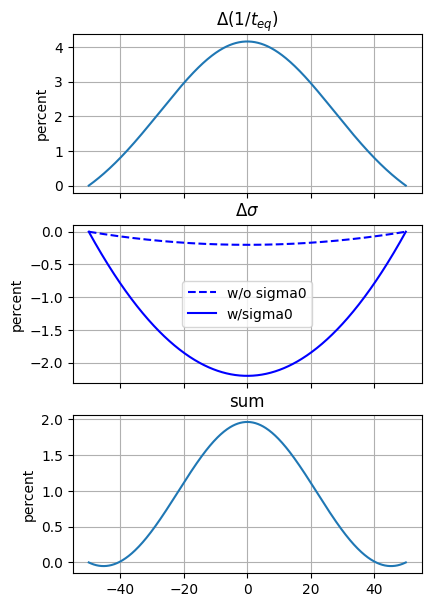

In [ ]:
# Parameters
GIfile =     "Variable teq.nml"
figurefile = "Variable teq.png"

sigmaI_corner, sigma0, c_r, sigmaI_QLC, Nbar, Nstar, h_layer, D, nu_kin, L, nx_crystal, t_eq, x_QLC, DoverL2pi2, Doverdeltax2 = \
    QLC.get_system_parameters(GIfile, AssignQuantity)
odemethod, tkeep_1Darr, Ntot_init_1D, NQLL_init_1D = \
    QLC.get_runtime_parameters(GIfile, nx_crystal, Nstar, Nbar, AssignQuantity)

dx = 2*L/nx_crystal
print('dx =',dx)

# tau_eq modification
t_eq_strategy = "gaussian2"
# t_eq_strategy = "gaussian4"
# t_eq_strategy = "two-peak"

match t_eq_strategy:
    case "gaussian2":
        width = AssignQuantity(40,'micrometer')
        t_eq_reduction = AssignQuantity(0.1,'dimensionless'); print('t_eq_reduction =', t_eq_reduction.to('%'))
        exponential_argument = -(x_QLC/width)**2
        intermediate = np.exp(exponential_argument)
        
    case "gaussian4":
        width = AssignQuantity(40,'micrometer')
        t_eq_reduction = AssignQuantity(0.1,'dimensionless'); print('t_eq_reduction =', t_eq_reduction.to('%'))
        exponential_argument = -(x_QLC/width)**4
        intermediate = np.exp(exponential_argument)
        
    case "two-peak":
        width = AssignQuantity(40,'micrometer')
        displacement = AssignQuantity(30,'micrometer')
        t_eq_reduction = AssignQuantity(0.15,'dimensionless'); print('t_eq_reduction =', t_eq_reduction.to('%'))
        exponential_argument1 = -((x_QLC-displacement)/width)**2
        exponential_argument2 = -((x_QLC+displacement)/width)**2
        intermediate = (np.exp(exponential_argument1) + np.exp(exponential_argument2))

t_eq_array_pint = t_eq * (1 -intermediate*t_eq_reduction)
t_eq_array = t_eq_array_pint.magnitude
t_eq_rate_array = 1/t_eq_array_pint
delta_t_eq_rate = (t_eq_rate_array-t_eq_rate_array[0])/t_eq_rate_array[0]
delta_t_eq_rate.ito('%')


# Mass diffusion length
mdl = np.sqrt(t_eq_array_pint*D)

# Plot them
fig, axs = plt.subplots(3,figsize=(4.5,7))

axs[0].plot(x_QLC.magnitude,delta_t_eq_rate)
axs[0].set_title(str('$\Delta (1/t_{eq})$'))
axs[0].set(ylabel=str(delta_t_eq_rate.units))

delta_sigma = (sigmaI_QLC-sigmaI_QLC[0])/(sigmaI_QLC[0]-sigma0); print(delta_sigma[0])
delta_sigma1 = (sigmaI_QLC-sigmaI_QLC[0])/sigmaI_QLC[0]; print(delta_sigma1[0])
delta_sigma.ito('%')
delta_sigma1.ito('%')
axs[1].plot(x_QLC.magnitude,delta_sigma1.magnitude,'--b',label='w/o sigma0')
axs[1].plot(x_QLC.magnitude,delta_sigma.magnitude,'-b',label='w/sigma0')
axs[1].set(ylabel=str(delta_sigma.units))
axs[1].set_title(r'$\Delta\sigma$')
axs[1].set(xlabel='x ('+str(x_QLC.units)+')')
axs[1].legend()

delta_sum = delta_sigma+delta_t_eq_rate
axs[2].plot(x_QLC.magnitude,delta_sum.magnitude)
axs[2].set(ylabel=str(delta_sum.units))
axs[2].set_title('sum')

            
# sigma_over_t_eq = delta_sigma/t_eq_array_pint
# axs[2].plot(x_QLC.magnitude,sigma_over_t_eq.magnitude)
# axs[2].set(ylabel=str(sigma_over_t_eq.units))
# axs[2].set_title(r'$(\sigma_I-\sigma_o) / t_{eq} $')
# axs[2].set(xlabel='x ('+str(x_QLC.units)+')')


for ax in axs:
    ax.grid(True)

for ax in axs.flat:
    ax.label_outer()


0.22 dimensionless 0.22 0.2
10 % elapsed time is 0.048 minutes
20 % elapsed time is 0.090 minutes
30 % elapsed time is 0.133 minutes
40 % elapsed time is 0.179 minutes
50 % elapsed time is 0.225 minutes
60 % elapsed time is 0.271 minutes
70 % elapsed time is 0.319 minutes
80 % elapsed time is 0.368 minutes
90 % elapsed time is 0.419 minutes
100% done
status =  0
message =  The solver successfully reached the end of the integration interval.
['message', 'nfev', 'njev', 'nlu', 'sol', 'status', 'success', 't', 't_events', 'y', 'y_events']


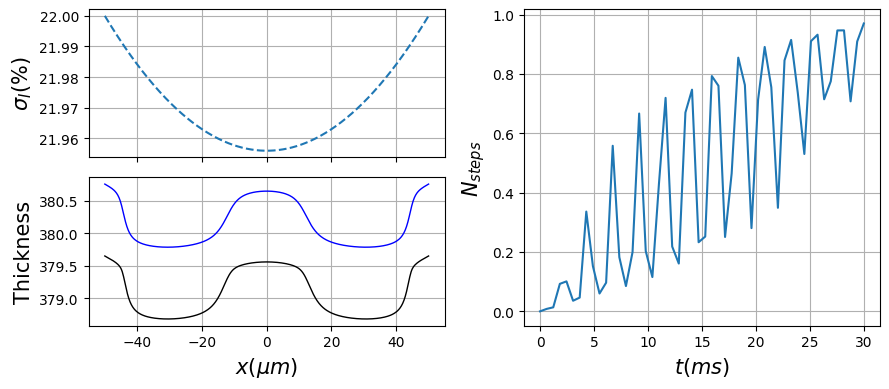

In [226]:
# Run the simulation in Cartesian space
Ntotkeep_1D, NQLLkeep_1D = run_f1d(\
           NQLL_init_1D,Ntot_init_1D,tkeep_1Darr,\
           Nbar, Nstar, sigma0, nu_kin, Doverdeltax2, t_eq, sigmaI_QLC,\
           AssignQuantity,\
           verbose=0, odemethod=odemethod) #!!!
Nicekeep_1D = Ntotkeep_1D-NQLLkeep_1D

# Graphical output
fig = QLC.report_1d_growth_results_with_sigma(\
        x_QLC,tkeep_1Darr.to('millisecond'),NQLLkeep_1D,Ntotkeep_1D,Nicekeep_1D,sigmaI_QLC.to('percent'))
fig.savefig(figurefile, dpi=200)